# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
## Evaluation step - Step 4

**Notebook by Alice DuVivier - April 2026**
- Reads in the csv files with qerror (from step 3) to find "winning" SOMs and plots sammon maps

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import sammon

## Section 1: Load training data

In [2]:
# set: path where the CSV files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/'

In [3]:
# set possible grid sizes. These are paired values.
som_grid_rows    = [3, 4, 5, 2, 3, 4]    # (y-axis)
som_grid_cols    = [3, 4, 5, 3, 4, 5]    # (x-axis)

In [4]:
# MANUAL CHANGING REQUIRED HERE
n = 2
# n = 0-5 (matches sizes set above), done: 0, 1, 3

som_row = som_grid_rows[n]
som_col = som_grid_cols[n]

In [5]:
# open training data
#fin = dir_in + 'mesaclip_training_data_alaska_psl_autumn_decadal.nc'
fin = dir_in + 'mesaclip_training_data_alaska_wind_vectors_autumn_decadal.nc'
subset = xr.open_dataset(fin)

# assign to numpy array object
subsetarray = subset['train_data'].values

In [6]:
# check the data dims/shape - should match the dims from the getting data notebook
print(subsetarray.shape)
# confirm there are no NaN values in array for training (should print False if no values)
print(np.isnan(subsetarray).any())

(49410, 4014)
False


In [7]:
# define shape
input_length = subsetarray.shape[1]

## Section 2: Load CSV training results

In [9]:
# read in the file with all the possible soms
#df = pd.read_csv(dir_in+'test_soms_qerror_alaska_psl_'+str(som_row)+'x'+str(som_col)+'.csv')
df = pd.read_csv(dir_in+'test_soms_qerror_alaska_wind_vectors_'+str(som_row)+'x'+str(som_col)+'.csv')

In [10]:
# sort values by q_error
sorted_df = df.sort_values(['q_error'])

# find and save the lowest qerror for top # (10)
all_n = sorted_df
top_n = sorted_df.head(20)
bottom_n = sorted_df.tail(20)
#print(top_n)

In [11]:
# grab the qerrors and make array against which to plot
qerr_all = sorted_df.q_error
xarr_all = np.arange(1,len(qerr_all)+1,1)
qerr_n = all_n.q_error
#qerr_n = top_n.q_error
xarr_n = np.arange(1,len(qerr_n)+1,1)

Plotting qerror for som: 5x5


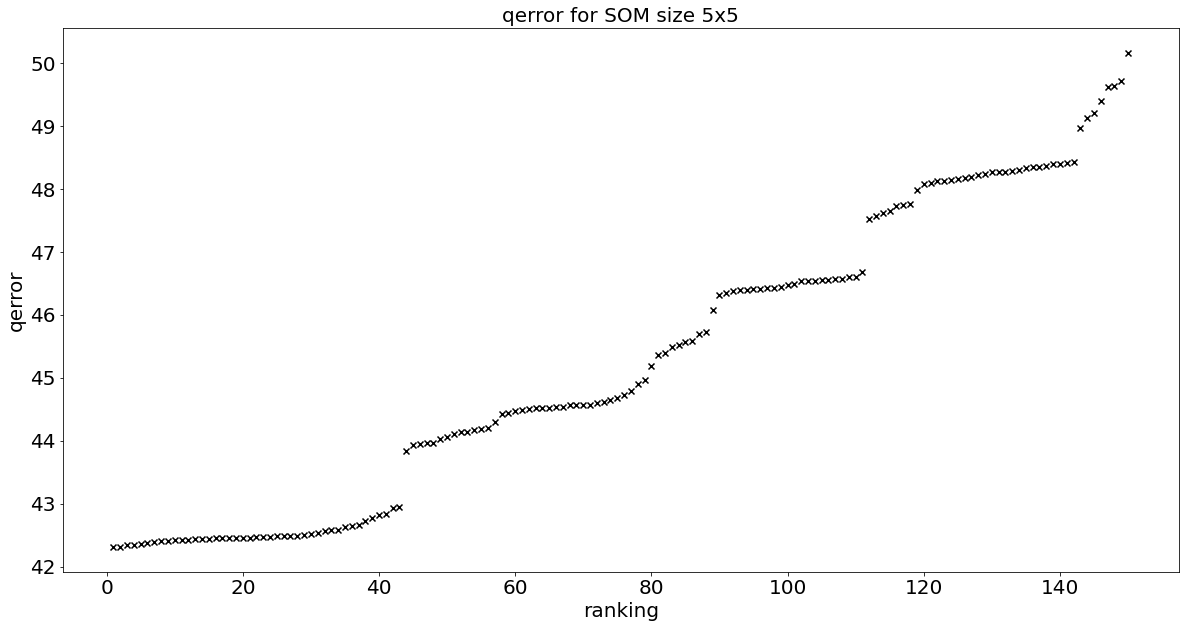

In [12]:
print('Plotting qerror for som: '+str(som_row)+'x'+str(som_col))

# set output name
#fout = dir_in+'som_evaluation/qerror_plot_alaska_psl_'+str(som_row)+'x'+str(som_col)+'.png'
fout = dir_in+'som_evaluation/qerror_plot_alaska_wind_vectors_'+str(som_row)+'x'+str(som_col)+'.png'
label_in = 'qerror for SOM size '+str(som_row)+'x'+str(som_col)
fs=20

# Actually plot figure now
fig = plt.figure(figsize=(20,10))

# plot all SOM qerror
ax = fig.add_subplot(1,1,1)
ax.scatter(xarr_all,qerr_all,marker='x',c='black')
plt.title(label_in,fontsize=fs)
plt.xlabel('ranking',fontsize=fs)
plt.ylabel('qerror',fontsize=fs)
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)

# save figure:
fig = plt.savefig(fout, bbox_inches='tight', dpi=200)

## Section 3: Plot Sammon Maps

In [ ]:
# Loop through the lowest values and load in the relevant pickle

for n in xarr_n:
    print(str(n)+'th lowest qerror')
    
    # set the training values
    qerr = all_n.iloc[n-1]['q_error'].item()
    sig = all_n.iloc[n-1]['sigma'].item()
    lr = all_n.iloc[n-1]['lr'].item()
    n_iter = int(all_n.iloc[n-1]['n_iter'].item())
    
    # construct the input and output name from this, set as output for figure names
    #fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
    #fout = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_rank_'+str(n)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
    fin = 'som_alaska_wind_vectors_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
    fout = 'som_alaska_wind_vectors_'+str(som_row)+'x'+str(som_col)+'_rank_'+str(n)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
    
    
    # open pickle
    with open(dir_in+'/pickles/'+fin+'.p', 'rb') as infile:
        som = pickle.load(infile)

    # Calculate sammon coordinates (y) for map and "map stress" (E)
    [y,E] = sammon.sammon(som.get_weights().reshape(som_col*som_row, input_length),2,display=1)

    # Plot Sammon map nodes
    fig = plt.figure(figsize=(10,8))
    plt.scatter(y[:,0], y[:,1], s=20, c='black', marker='o')

    # Add lines between nodes
    tmp = np.reshape(y,(som_col,som_row,2))
    len_x, len_y, len_z = tmp.shape
    
    # add vertical lines
    for i in range(len_x-1):
        for j in range(len_y):
            plt.plot(tmp[i:i+2,j,0],tmp[i:i+2,j,1],c='black')
    
    # add horizontal lines
    for i in range(len_x):
        for j in range(len_y-1):
            plt.plot(tmp[i,j:j+2,0],tmp[i,j:j+2,1],c='black')  
    
    plt.xticks([])
    plt.yticks([])
    plt.title(r"sammon map" "\n" r"map stress = "+str(E), fontsize=12)
    
    # save figure
    fout = dir_in+'sammons/'+fout+'_sammon.png'
    plt.savefig(fout, bbox_inches='tight', dpi=200)
